# 5. Conclusiones

**Materia:** 72.75 Aprendizaje Automático (Machine Learning) · ITBA · 2026 Q2 · TP2: Clasificación supervisada  
**Integrantes:** Diego Emiliano Godinez Ortega, Thomas Michael Spitzner, Guillermo Arturo Ledesma Campos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA_PATH = Path("../data")
FIGURES_PATH = Path("../figures")

## Ranking de modelos (validación cruzada, set 1)
1. **Random Forest** (0.798): profundidad limitada; no lineal e invariante a escala y colinealidad.
2. **KNN** (0.786, k = 401): buen ranking, pero F1 bajo: con k grande vota casi siempre `no`.
3. **Naive Bayes** (0.777): alto sesgo, sin sobreajuste.
4. **SVM** (0.776, C = 0.01): casi sin sobreajuste; el más costoso de entrenar.

In [2]:
resumen_modelos = pd.DataFrame({
    "Modelo": ["Random Forest", "KNN", "Naive Bayes", "SVM"],
    "ROC-AUC (Val)": [0.798, 0.786, 0.777, 0.776],
    "F1-score (Val)": [0.465, 0.317, 0.421, 0.404],
    "Generalization Gap": [0.028, 0.012, 0.000, 0.002],
    "Diagnóstico Sesgo-Varianza": [
        "Bajo sesgo + varianza controlada (profundidad limitada)",
        "Varianza controlada con k grande, sesgo hacia la clase mayoritaria",
        "Alto sesgo (frontera rígida paramétrica)",
        "Sesgo medio, casi sin sobreajuste"
    ]
}).set_index("Modelo")
resumen_modelos

,ROC-AUC (Val),F1-score (Val),Generalization Gap,Diagnóstico Sesgo-Varianza
Modelo,,,,
Random Forest,0.798,0.465,0.028,Bajo sesgo + varianza controlada (profundidad ...
KNN,0.786,0.317,0.012,"Varianza controlada con k grande, sesgo hacia ..."
Naive Bayes,0.777,0.421,0.000,Alto sesgo (frontera rígida paramétrica)
SVM,0.776,0.404,0.002,"Sesgo medio, casi sin sobreajuste"


### Por defecto vs. ajustados

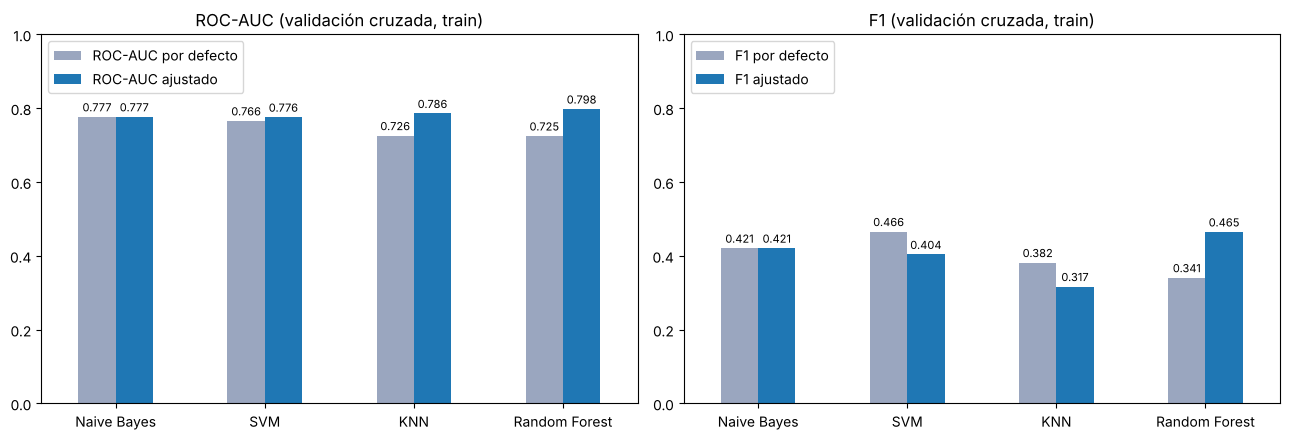

In [3]:
model_scores = pd.DataFrame({
    "Modelo": ["Naive Bayes", "SVM", "KNN", "Random Forest"],
    "ROC-AUC por defecto": [0.777, 0.766, 0.726, 0.725],
    "ROC-AUC ajustado": [0.777, 0.776, 0.786, 0.798],
    "F1 por defecto": [0.421, 0.466, 0.382, 0.341],
    "F1 ajustado": [0.421, 0.404, 0.317, 0.465],
}).set_index("Modelo")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ["ROC-AUC", "F1"]):
    model_scores[[f"{metric} por defecto", f"{metric} ajustado"]].plot(
        kind="bar", ax=ax, rot=0, color=["#9AA6BF", "#1f77b4"])
    for bars in ax.containers:
        ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8)
    ax.set_title(f"{metric} (validación cruzada, train)")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "16_resumen_modelos.png", dpi=300, bbox_inches="tight")
plt.show()

## ¿Se cumplen los supuestos?
- Independencia (NB): no, el bloque económico está muy correlacionado (VIF 31–64).
- Normalidad (NB): no, hay variables binarias y asimétricas.
- Escala (SVM, KNN): requieren `StandardScaler`.
- Linealidad: relaciones no lineales → SVM con kernel RBF y árboles.
- Desbalance: `class_weight="balanced"` y métricas adecuadas.

In [4]:
supuestos = pd.DataFrame({
    "Supuesto Teórico": [
        "Independencia condicional entre predictoras",
        "Distribución Normal (Gaussiana) de las variables",
        "Separabilidad lineal de las clases",
        "Invarianza a la escala de las variables",
        "Balance simétrico de clases"
    ],
    "Evidencia en los Datos": [
        "Variables macroeconómicas correlacionadas",
        "Distribuciones asimétricas y variables 0/1",
        "Relaciones no lineales con y",
        "Variables continuas con rangos dispares",
        "Desbalance 88.7% 'no' vs 11.3% 'yes'"
    ],
    "Naive Bayes": ["✘ Violado", "✘ Violado", "N/A", "✔ Cumple", "⚠️ Sensible"],
    "SVM": ["✔ Robusto", "✔ Robusto", "⚠️ Requiere kernel RBF", "⚠️ Requiere Scaler", "⚠️ Sensible"],
    "KNN": ["⚠️ Distorsiona distancias", "✔ Robusto", "✔ Flexible", "⚠️ Requiere Scaler", "⚠️ Sensible"],
    "Random Forest": ["✔ Robusto", "✔ Robusto", "✔ Flexible", "✔ Robusto", "⚠️ Requiere balanced"]
}).set_index("Supuesto Teórico")
supuestos

,Evidencia en los Datos,Naive Bayes,SVM,KNN,Random Forest
Supuesto Teórico,,,,,
Independencia condicional entre predictoras,Variables macroeconómicas correlacionadas,✘ Violado,✔ Robusto,⚠️ Distorsiona distancias,✔ Robusto
Distribución Normal (Gaussiana) de las variables,Distribuciones asimétricas y variables 0/1,✘ Violado,✔ Robusto,✔ Robusto,✔ Robusto
Separabilidad lineal de las clases,Relaciones no lineales con y,N/A,⚠️ Requiere kernel RBF,✔ Flexible,✔ Flexible
Invarianza a la escala de las variables,Variables continuas con rangos dispares,✔ Cumple,⚠️ Requiere Scaler,⚠️ Requiere Scaler,✔ Robusto
Balance simétrico de clases,Desbalance 88.7% 'no' vs 11.3% 'yes',⚠️ Sensible,⚠️ Sensible,⚠️ Sensible,⚠️ Requiere balanced


## Errores más relevantes
- **FN** (cliente que habría contratado y no se llama): venta perdida → el más grave.
- **FP** (llamada sin éxito): solo el costo de la llamada.

→ Conviene priorizar el recall (bajar el umbral).

## Limitaciones y mejoras
**Limitaciones**
- Datos de 2008–2010: dependen del ciclo económico.
- `euribor3m` (312 valores) ≈ fecha de la llamada: con split aleatorio, train y test comparten fechas → estimación optimista para campañas futuras.
- Sin `duration`, el techo es ROC-AUC ≈ 0.80.

**Mejoras**
- Elegir el umbral con una matriz de costos FN / FP.
- Validación temporal (entrenar con meses anteriores, evaluar con posteriores).
- Probar boosting y combinar RF + KNN.

## Conclusión
Random Forest (`max_depth = 8`, set 1) es el mejor modelo: ROC-AUC 0.798 en validación y 0.813 en test.